### **Filter and Convolution**

___

**C1 (ทฤษฎี + โค้ด) Convolution คือ "เลื่อน คูณ บวก" — อ่าน ThinkDSP บทที่ 8 หัวข้อ 8.1 Smoothing และ 8.2 Convolution**
  - **ทำ:**
    - สร้าง notebook ใหม่ `notebooks/07_Filters.ipynb`
    - ทำนายก่อนรัน: convolution ของ `x = [1, 2, 3, 4]` กับ `h = [0.5, 0.5]` คิดมือ เขียนผลลง markdown
    > คิดมือแล้วผลลัพธ์ของการ convolution มีค่าเท่ากับ [0.5, 1.5, 2.5, 3.5, 2]
    - สร้างไฟล์ `dsp/filters.py` → เขียน `convolve(x, h)` พร้อม docstring ใช้ loop ซ้อน 2 ชั้นตามสูตร $y[n] = \sum_k h[k]\,x[n-k]$
    - ความยาวผลลัพธ์ = `len(x) + len(h) - 1` → ข้าม `x[n-k]` ที่ index อยู่นอกช่วง 0 ถึง `len(x) - 1`
    - ทดสอบกับตัวเลขที่ทำนายไว้ → เช็ค `np.allclose` กับ `np.convolve(x, h)`
    - ทดสอบ impulse: `convolve([0, 0, 1, 0, 0], [1, 2, 3])` → print ผล
  - **ตอบ:**
    1. `len` ของผลลัพธ์ `[1, 2, 3, 4]` กับ `[0.5, 0.5]` ได้เท่าไร
    > จากสูตรการคำนวณหาขนาดของ array ของ output array จากการทำ Convolution
    > 
    > $x_n+h_n-1$ เมื่อ $x_n$ : ขนาดของ input signal array และ $h_n$ : ขนาดของ filters
    >
    > ซึ่งมีค่าเท่ากับ $x_n+h_n-1 = 4+2-1 = 5$ 
    2. `np.allclose` กับ `np.convolve` ได้ True หรือ False
    > ผลลัพธ์อยู่ใน dsp/filters.py มีการตรวจสอบด้วย np.allclose() แล้วผลลัพธ์มีค่าเท่ากับ True
    3. ผล impulse test มีตัวเลข `[1, 2, 3]` เริ่มที่ index ไหน
    > ผล impulse test มีตัวเลขเริ่มต้นที่ index = 2 และจบที่ index = 4
  - **เสร็จเมื่อ:** import `convolve` จาก `dsp.filters` ได้ / ผลได้ `[0.5, 1.5, 2.5, 3.5, 2.0]` / `np.allclose` ได้ True / impulse test ได้ `[0, 0, 1, 2, 3, 0, 0]` และตอบครบ 3 ข้อ

In [1]:
%load_ext autoreload
%autoreload 2

import sys, os
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio

sys.path.insert(0, os.path.abspath(".."))
from dsp.filters import convolve
from dsp.signal_generator import make_time, create_sin

In [2]:
x = np.array([1,2,3,4])
h = np.array([0.5, 0.5])

print(convolve(x,h))
print("Verify whether the value of np.convolve(x,h) = convolve(x,h) by using np.allclose()")
print(f"{np.allclose(convolve(x,h),np.convolve(x,h))}")

# Test with impulse 
print(f"Test convolve() with impulse : {convolve([0, 0, 1, 0, 0], [1, 2, 3])}")

[0.5 1.5 2.5 3.5 2. ]
Verify whether the value of np.convolve(x,h) = convolve(x,h) by using np.allclose()
True
Test convolve() with impulse : [0. 0. 1. 2. 3. 0. 0.]


**C2 (โค้ด + หู) Moving average เป็น low-pass filter**
  - **ทำ:**
    - `sr = 8000` สร้าง `t` 1 วินาที → `x = create_sin(1, 200, t) + create_sin(0.5, 2500, t)`
    - kernel moving average 8 จุด: `h = np.ones(8) / 8`
    - `y = np.convolve(x, h, mode='same')` → print `len(y)`
    - `X = np.abs(np.fft.rfft(x))`, `Y = np.abs(np.fft.rfft(y))`, `freqs = np.fft.rfftfreq(len(x), 1/sr)`
    - หา index ของ 200 Hz กับ 2500 Hz → print gain `Y / X` ที่สองความถี่นี้
    - ฟัง `x` กับ `y` ด้วย `Audio(..., rate=sr)`
  - **เครื่องมือใหม่:**
    - `np.convolve([1, 2, 3], [1, 1], mode='same')` → `[1, 3, 5]` (ตัดให้ยาวเท่า input ส่วนแบบ default ได้ `[1, 3, 5, 3]`)
  - **ใบ้:** C1 ผ่านแล้วใช้ `np.convolve` แทน `convolve` ของเราได้ เพราะเร็วกว่ามาก
  - **ตอบ:**
    1. gain ที่ 200 Hz ได้เท่าไร
    > gain ที่ 200 Hz มีค่าประมาณ 0.936
    2. gain ที่ 2500 Hz ได้เท่าไร
    > gain ที่ 2500 มีค่าประมาณ 0.150
    3. ฟัง `y` แล้วเสียงไหนเบาลงชัด: เสียงทุ้ม หรือเสียงแหลม
    > หลังจากฟัง y แล้วเสียงที่เบาลงชัดเจนคือ เสียงแหลมที่มีความถี่สูง เพราะ สิ่งที่กำลังทำคือการทำ low-pass filters หรือตัวกรองความถี่ต่ำผ่าน จะยอมให้ความถี่ต่ำผ่านแต่ความถี่สูงไม่ให้ผ่าน เสียงที่ได้ยินเสียงแหลมจึงเบาลงชัดเจน
  - **เสร็จเมื่อ:** `len(y)` ได้ 8000 / index ได้ 200 กับ 2500 / gain ≈0.936 กับ ≈0.150 และตอบครบ 3 ข้อ

In [3]:
sr = 8000
t = make_time(0, 1, sr)
x = create_sin(1, 200, t) + create_sin(0.5, 2500, t)
h = np.ones(8)/8 

y = np.convolve(x, h, mode="same")
print(f"The output signal array (y) size : {len(y)}")

X = np.abs(np.fft.rfft(x))
Y = np.abs(np.fft.rfft(y))
freqs = np.fft.rfftfreq(len(x), 1/sr)

freqs_200 = np.argmin(np.abs(freqs - 200))
freqs_2500 = np.argmin(np.abs(freqs - 2500))

X_200 = X[freqs_200]
Y_200 = Y[freqs_200]
X_2500 = X[freqs_2500]
Y_2500 = Y[freqs_2500]
print(f"Index of 200 Hz : {freqs_200} and Gain at 200 Hz : {round(Y_200/X_200,3)}")
print(f"Index of 2500 Hz : {freqs_2500} and Gain at 2500 Hz : {round(Y_2500/X_2500,3)}")

The output signal array (y) size : 8000
Index of 200 Hz : 200 and Gain at 200 Hz : 0.936
Index of 2500 Hz : 2500 and Gain at 2500 Hz : 0.15


In [4]:
# Listen x signal (the signal without low-pass filter)
Audio(x, rate=sr)

In [5]:
# Listen y signal (the signal with low-pass filters)
Audio(y, rate=sr)

**C3 (โค้ด + สังเกต) Frequency response = FFT ของ kernel — อ่าน ThinkDSP หัวข้อ 8.3 The frequency** domain
  - **ทำ:**
    - `H = np.abs(np.fft.rfft(h, n=8000))` → `freqs_h = np.fft.rfftfreq(8000, 1/sr)` → print `len(H)`
    - print `H` ที่ 200 Hz กับ 2500 Hz → เทียบกับ gain จาก C2
    - ใช้ `for M in [4, 8, 16]:` (ห้าม copy โค้ด 3 ชุด) สร้าง `h = np.ones(M) / M` แล้วคำนวณ `H`
    - ในลูป: หาความถี่แรกที่ `H` ลงไปเป็น 0 (`H < 1e-6`) → print คู่กับ `M`
    - ในลูป: พล็อต `H` เทียบ `freqs_h` ทั้ง 3 เส้นในกราฟเดียว (มี legend บอก M)
  - **เครื่องมือใหม่:**
    - `np.fft.rfft([1, 1], n=4)` → เติม 0 ท้ายให้ยาว 4 ก่อน FFT ได้ bin ละเอียดขึ้น
    - `np.argmax(np.array([5, 3, 0, 2]) < 1)` → 2 คือ index แรกที่เงื่อนไขเป็น True
  - **ตอบ:**
    1. `M = 8` มี `H` ที่ 2500 Hz เท่าไร
    > ที่ `M = 8` มี `H` ที่ 2500 Hz เท่ากับ 0.15 ซึ่งมีค่าเหมือนกับ C2 
    2. `M = 8` มี `H` เป็น 0 ครั้งแรกที่กี่ Hz
    > ที่ `M = 8` มี `H` เป็น 0 ครั้งแรกที่ความถี่เท่ากับ 1000 Hz
    3. `M` ไหนที่ปล่อยให้ความถี่ผ่านได้แคบที่สุด
    > จากการสังเกตกราฟ `M` ที่ปล่อยให้ความถี่ผ่านได้แคบที่สุด คือ M = 16
  - **เสร็จเมื่อ:** `len(H)` ได้ 4001 / M = 8: `H` ที่ 200 Hz ≈0.936 และที่ 2500 Hz ≈0.150 ตรงกับ C2 / ความถี่ที่เป็น 0 ครั้งแรก M = 4, 8, 16 ได้ 2000, 1000, 500 Hz / มีกราฟ 3 เส้นจากลูปเดียว และตอบครบ 3 ข้อ

The filter coefficients (h) size after FFT : 4001
The filter coefficients (h) at 200 Hz : 0.936
The filter coefficients (h) at 2500 Hz : 0.15
M = 4 and the first frequency the approches 0 is 2000.0
M = 8 and the first frequency the approches 0 is 1000.0
M = 16 and the first frequency the approches 0 is 500.0


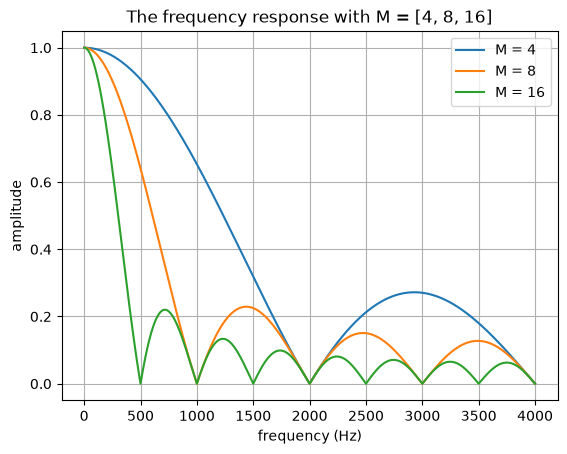

In [6]:
H = np.abs(np.fft.rfft(h, n=8000))
freqs_h = np.fft.rfftfreq(8000, 1/sr)

freqs_h_200 = np.argmin(np.abs(freqs_h - 200))
freqs_h_2500 = np.argmin(np.abs(freqs_h - 2500))
H_200 = H[freqs_h_200]
H_2500 = H[freqs_h_2500]

print(f"The filter coefficients (h) size after FFT : {len(H)}")
print(f"The filter coefficients (h) at 200 Hz : {round(H_200,3)}")
print(f"The filter coefficients (h) at 2500 Hz : {round(H_2500,3)}")

fig, axes = plt.subplots()
axes.set(xlabel="frequency (Hz)", ylabel="amplitude", title="The frequency response with M = [4, 8, 16]")
axes.grid()

for M in [4, 8, 16]:
    h = np.ones(M)/M 
    H = np.abs(np.fft.rfft(h, n=8000))

    n = np.argmax(H < 1e-6)
    print(f"M = {M} and the first frequency the approches 0 is {freqs_h[n]}")

    axes.plot(freqs_h, H, label=f"M = {M}")
    axes.legend(loc="upper right")